# AP2 | Aprendizado de Máquina
## Previsão da demanda horária de bicicletas compartilhadas

**Disciplina:** Aprendizado de Máquina — IBMEC

**Aluno (a):** Marcelle Lohane

**Repositório:** https://github.com/marcelleloha/AP2_Modelo_Bicicletas

## Introdução

### Contexto
Uma operadora de bicicletas compartilhadas precisa estimar quantas locações ocorrerão em cada hora. A partir de observações históricas de calendário e de condições meteorológicas, este notebook constrói um **modelo de regressão** para prever a variável `demanda_bicicletas` (quantidade de locações na hora).

### O que vamos fazer
1. **Análise exploratória** dos dados e formulação de, no mínimo, três hipóteses justificadas sobre o comportamento da demanda.
2. **Baseline** de regressão usando apenas os atributos originais, com representação adequada da data/hora e da variável categórica.
3. **Engenharia de atributos**: pelo menos oito atributos derivados, cada um com justificativa e registro de resultado.
4. **Comparação controlada**: o mesmo algoritmo, com a mesma validação e os mesmos hiperparâmetros, antes e depois da engenharia de atributos.
5. **Segundo algoritmo** de regressão, comparado por MAE, RMSE e R².
6. **Ablação**: remoção de grupos de atributos para medir a contribuição de cada um.
7. **Função de predição** que recebe registros inéditos apenas com as cinco entradas originais.

### Dados
| Coluna | Significado |
|---|---|
| `data_hora` | Data e hora do período observado |
| `temperatura_c` | Temperatura do ar em °C |
| `umidade_pct` | Umidade relativa em % |
| `vento_kmh` | Velocidade do vento em km/h |
| `condicao_tempo` | `limpo`, `nublado`, `chuva` ou `chuva_forte` |
| `demanda_bicicletas` | Quantidade de locações na hora (**variável-alvo**) |

- **`base_alunos.csv`**: 14.616 registros horários, de 01/01/2024 a 31/08/2025.
- **`teste_features_sem_alvo.csv`**: entradas de 01/09/2025 a 31/12/2025, sem o alvo, usadas apenas na previsão final.

Os arquivos são lidos **diretamente do repositório no GitHub**, pelo link *raw*. Não é necessário fazer upload nem montar o Google Drive.

### Protocolo de validação
- **Treino:** 01/01/2024 a 30/04/2025 (11.664 horas).
- **Validação:** 01/05/2025 a 31/08/2025 (2.952 horas).
- Os períodos **não são embaralhados**. Toda transformação que depende de estatísticas é ajustada **apenas no treino**, dentro de um `Pipeline`.
- A validação não é usada para escolher atributos. Só depois da seleção do modelo ele é retreinado com a base completa para gerar `previsoes_teste.csv`.

### Como executar
**Google Colab (recomendado)**
1. Abra o notebook no Colab.
2. Menu **Ambiente de execução → Executar tudo**.
3. Ao final, o arquivo `previsoes_teste.csv` é gerado na pasta do ambiente (painel **Arquivos**, à esquerda).

**Execução local**
```bash
git clone https://github.com/marcelleloha/AP2_Modelo_Bicicletas.git
cd AP2_Modelo_Bicicletas
pip install -r requirements.txt
jupyter notebook
```
Abra o notebook e execute todas as células em ordem. É necessária conexão com a internet para ler os dados do GitHub.

### Reprodutibilidade
- As versões das bibliotecas são exibidas na seção 1 e fixadas no `requirements.txt`.
- Os modelos com componente aleatório usam `random_state = 42`.
- O notebook roda de ponta a ponta, sem passos manuais.

### Estrutura do notebook
1. Configuração do ambiente
2. Carga dos dados
3. Divisão temporal treino/validação
4. Análise exploratória
5. Baseline
6. Engenharia de atributos
7. Comparação controlada: antes × depois
8. Segundo algoritmo
9. Ablação
10. Análise crítica dos erros
11. Modelo final e função de predição
12. Conclusões
13. Declaração de uso de IA

# 1. Configuração do ambiente

## 1.1 Importação das bibliotecas

In [1]:
# Importando as bibliotecas necessárias
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

# Configurando o estilo visual dos gráficos
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Configurando a exibição das tabelas
pd.set_option('display.max_columns', 50)

## 1.2 Versões das bibliotecas

In [2]:
# Verificando as versões das bibliotecas
print("Versões das bibliotecas:")
print(f"  numpy       : {np.__version__}")
print(f"  pandas      : {pd.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  seaborn     : {sns.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")

Versões das bibliotecas:
  numpy       : 2.4.6
  pandas      : 2.2.3
  matplotlib  : 3.10.0
  seaborn     : 0.13.2
  scikit-learn: 1.6.1


# 2. Carga dos dados

## 2.1 Leitura da base

In [3]:
# Carregando o dataset direto do GitHub
url = "https://raw.githubusercontent.com/marcelleloha/AP2_Modelo_Bicicletas/main/base_alunos.csv"
df_raw = pd.read_csv(url)

print(f"Dimensões do dataset: {df_raw.shape}")
df_raw.info()

Dimensões do dataset: (14616, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14616 entries, 0 to 14615
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   data_hora           14616 non-null  object 
 1   temperatura_c       14616 non-null  float64
 2   umidade_pct         14616 non-null  float64
 3   vento_kmh           14616 non-null  float64
 4   condicao_tempo      14616 non-null  object 
 5   demanda_bicicletas  14616 non-null  int64  
dtypes: float64(3), int64(1), object(2)
memory usage: 685.3+ KB


## 2.2 Conversão da data/hora e ordenação

In [4]:
# Convertendo a coluna de data/hora e ordenando cronologicamente
df_raw['data_hora'] = pd.to_datetime(df_raw['data_hora'])
df = df_raw.sort_values('data_hora').reset_index(drop=True)

print("Primeiras 5 linhas do dataset:")
display(df.head())
print(df.dtypes)

Primeiras 5 linhas do dataset:


,data_hora,temperatura_c,umidade_pct,vento_kmh,condicao_tempo,demanda_bicicletas
0,2024-01-01 00:00:00,20.8,84.1,8.2,nublado,54
1,2024-01-01 01:00:00,18.7,65.5,7.4,limpo,52
2,2024-01-01 02:00:00,13.1,68.8,3.8,limpo,24
3,2024-01-01 03:00:00,18.3,50.5,4.7,limpo,33
4,2024-01-01 04:00:00,21.4,72.8,16.9,limpo,59


data_hora             datetime64[ns]
temperatura_c                float64
umidade_pct                  float64
vento_kmh                    float64
condicao_tempo                object
demanda_bicicletas             int64
dtype: object


# 3. Divisão temporal treino/validação

Seguindo o protocolo do enunciado, os dados foram divididos por data, sem embaralhamento: **treino** de 01/01/2024 a 30/04/2025 (11.664 horas) e **validação** de 01/05/2025 a 31/08/2025 (2.952 horas). A divisão é feita antes da análise exploratória, de modo que todas as análises e decisões sobre atributos usam apenas o conjunto de treino.

In [5]:
# Separando treino e validação pelo corte temporal obrigatório (sem embaralhar)
features = ['data_hora', 'temperatura_c', 'umidade_pct', 'vento_kmh', 'condicao_tempo']
target = 'demanda_bicicletas'

corte = '2025-05-01'
treino = df['data_hora'] < corte

X_train, y_train = df.loc[treino, features], df.loc[treino, target]
X_val,   y_val   = df.loc[~treino, features], df.loc[~treino, target]

# Base de treino completa (com o alvo) para a análise exploratória
df_train = df.loc[treino].copy()

print("=" * 60)
print("DIVISÃO TEMPORAL CONCLUÍDA")
print("=" * 60)
print(f"Treino   : {X_train.shape[0]} amostras ({X_train['data_hora'].min():%d/%m/%Y} a {X_train['data_hora'].max():%d/%m/%Y})")
print(f"Validação: {X_val.shape[0]} amostras ({X_val['data_hora'].min():%d/%m/%Y} a {X_val['data_hora'].max():%d/%m/%Y})")

DIVISÃO TEMPORAL CONCLUÍDA
Treino   : 11664 amostras (01/01/2024 a 30/04/2025)
Validação: 2952 amostras (01/05/2025 a 31/08/2025)


# 4. Análise exploratória

## 4.1 Qualidade dos dados

### 4.1.1 Valores nulos e duplicados

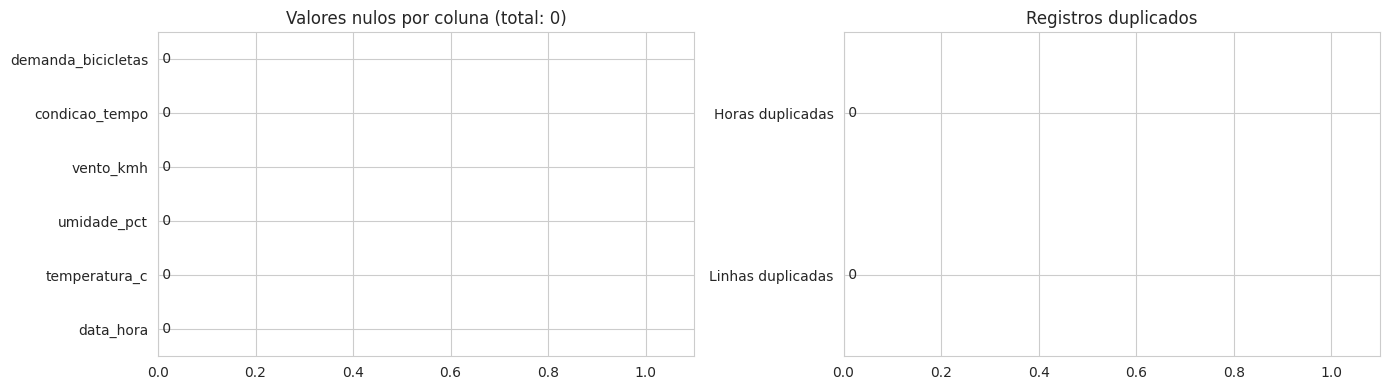

In [6]:
# Visualizando valores nulos e duplicados por coluna
nulos = df.isna().sum()
duplicados = pd.Series({'Linhas duplicadas': df.duplicated().sum(),
                        'Horas duplicadas' : df['data_hora'].duplicated().sum()})

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
nulos.plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_xlim(0, max(1, nulos.max()) * 1.1)
axes[0].set_title(f'Valores nulos por coluna (total: {nulos.sum()})')
for i, v in enumerate(nulos):
    axes[0].text(v, i, f' {v}', va='center')

duplicados.plot(kind='barh', ax=axes[1], color='indianred')
axes[1].set_xlim(0, max(1, duplicados.max()) * 1.1)
axes[1].set_title('Registros duplicados')
for i, v in enumerate(duplicados):
    axes[1].text(v, i, f' {v}', va='center')

plt.tight_layout()
plt.show()

### 4.1.2 Continuidade temporal

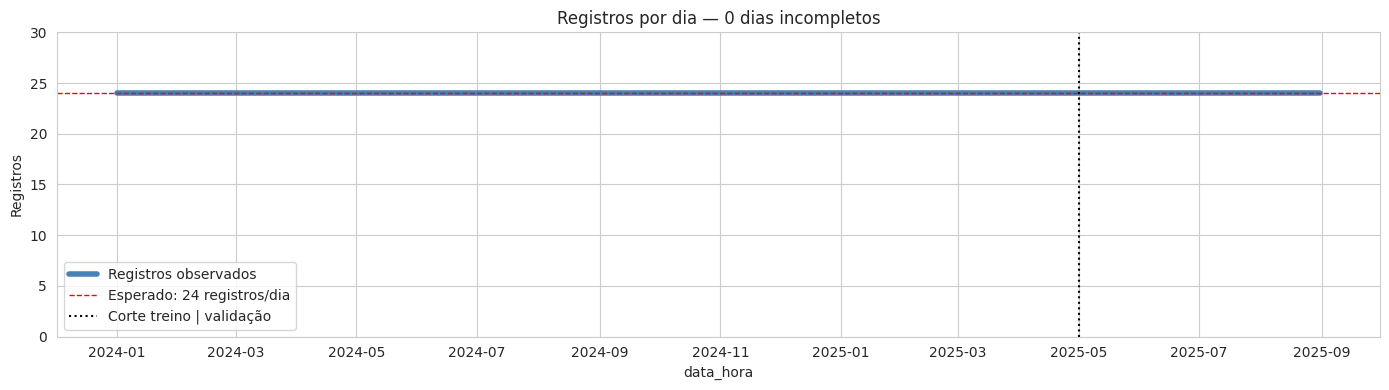

In [7]:
# Verificando a continuidade temporal: cada dia deveria ter 24 registros
registros_dia = df.groupby(df['data_hora'].dt.date).size()

fig, ax = plt.subplots(figsize=(14, 4))
registros_dia.plot(ax=ax, color='steelblue', linewidth=4, label='Registros observados')
ax.axhline(24, color='red', linestyle='--', linewidth=1, label='Esperado: 24 registros/dia')
ax.axvline(pd.Timestamp('2025-05-01'), color='black', linestyle=':', label='Corte treino | validação')
ax.set_ylim(0, 30)
ax.set_title(f'Registros por dia — {(registros_dia != 24).sum()} dias incompletos')
ax.set_ylabel('Registros')
ax.legend()
plt.tight_layout()
plt.show()

### 4.1.3 Faixas de valores plausíveis

In [8]:
# Verificando valores fisicamente impossíveis
num_features = ['temperatura_c', 'umidade_pct', 'vento_kmh', target]
limites = {'temperatura_c': (-5, 50), 'umidade_pct': (0, 100), 'vento_kmh': (0, 100), target: (0, np.inf)}

checagem = pd.DataFrame({
    c: {'Mínimo': df[c].min(), 'Máximo': df[c].max(),
        'Limite inferior': lim[0], 'Limite superior': lim[1],
        'Fora da faixa': ((df[c] < lim[0]) | (df[c] > lim[1])).sum()}
    for c, lim in limites.items()
}).T
display(checagem)

,Mínimo,Máximo,Limite inferior,Limite superior,Fora da faixa
temperatura_c,6.9,44.7,-5.0,50.0,0.0
umidade_pct,32.0,99.0,0.0,100.0,0.0
vento_kmh,0.0,38.0,0.0,100.0,0.0
demanda_bicicletas,0.0,199.0,0.0,inf,0.0


## 4.2 Estatística descritiva

### 4.2.1 Variáveis numéricas

In [9]:
# Calculando a estatística descritiva das variáveis numéricas (apenas no treino)
descritiva = df_train[num_features].describe().T
descritiva['assimetria'] = df_train[num_features].skew()
descritiva['curtose'] = df_train[num_features].kurt()
descritiva['coef_variacao_%'] = descritiva['std'] / descritiva['mean'] * 100

print("=" * 60)
print("ESTATÍSTICA DESCRITIVA — CONJUNTO DE TREINO")
print("=" * 60)
display(descritiva.round(2))

ESTATÍSTICA DESCRITIVA — CONJUNTO DE TREINO


,count,mean,std,min,25%,50%,75%,max,assimetria,curtose,coef_variacao_%
temperatura_c,11664.0,24.83,5.98,6.9,20.4,25.2,29.4,44.7,-0.14,-0.59,24.07
umidade_pct,11664.0,68.99,10.38,32.4,61.9,69.1,76.0,99.0,-0.03,-0.12,15.05
vento_kmh,11664.0,9.44,6.38,0.0,4.7,8.1,12.7,38.0,1.26,2.03,67.56
demanda_bicicletas,11664.0,89.18,40.61,0.0,56.0,85.0,122.0,199.0,0.24,-0.84,45.54


### 4.2.2 Variável categórica

In [10]:
# Analisando a frequência da variável categórica
freq = pd.DataFrame({
    'Frequência (horas)': df_train['condicao_tempo'].value_counts(),
    'Percentual (%)': df_train['condicao_tempo'].value_counts(normalize=True) * 100,
    'Demanda média (locações/h)': df_train.groupby('condicao_tempo')[target].mean(),
}).reindex(['limpo', 'nublado', 'chuva', 'chuva_forte'])

display(freq.round(2))

,Frequência (horas),Percentual (%),Demanda média (locações/h)
condicao_tempo,,,
limpo,9275,79.52,93.82
nublado,1191,10.21,82.09
chuva,964,8.26,63.61
chuva_forte,234,2.01,46.66


## 4.3 Outliers

### 4.3.1 Critério IQR

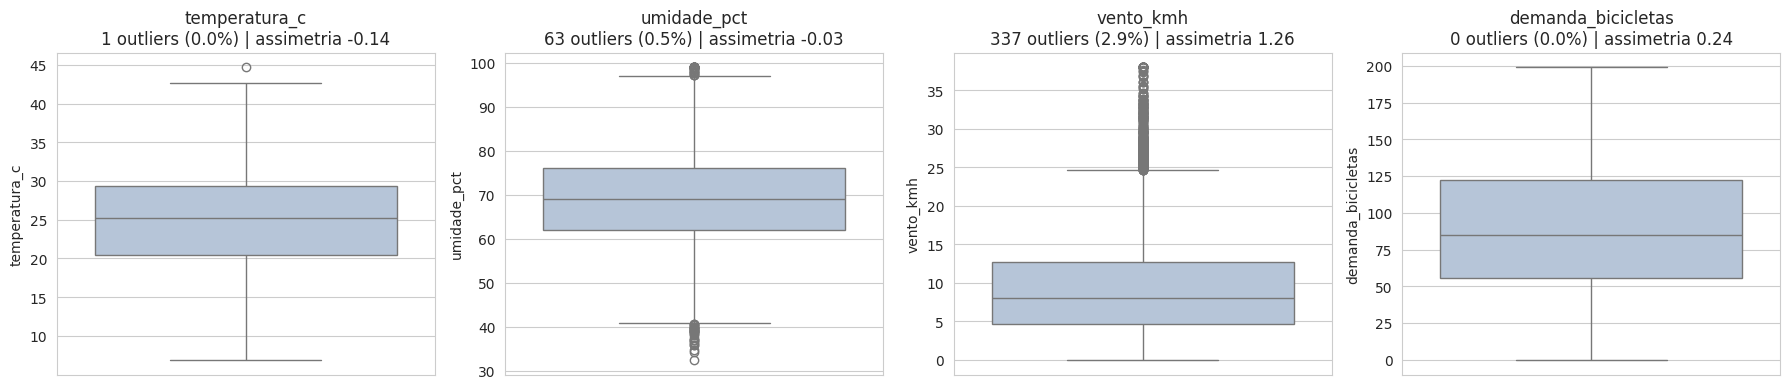

In [11]:
# Identificando outliers pelo critério IQR (apenas no treino)
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, num_features):
    inf, sup = limites_iqr(df_train[c])
    n_out = ((df_train[c] < inf) | (df_train[c] > sup)).sum()
    sns.boxplot(y=df_train[c], ax=ax, color='lightsteelblue')
    ax.set_title(f'{c}\n{n_out} outliers ({n_out / len(df_train):.1%}) | assimetria {df_train[c].skew():.2f}')
plt.tight_layout()
plt.show()

### 4.3.2 Investigação do vento

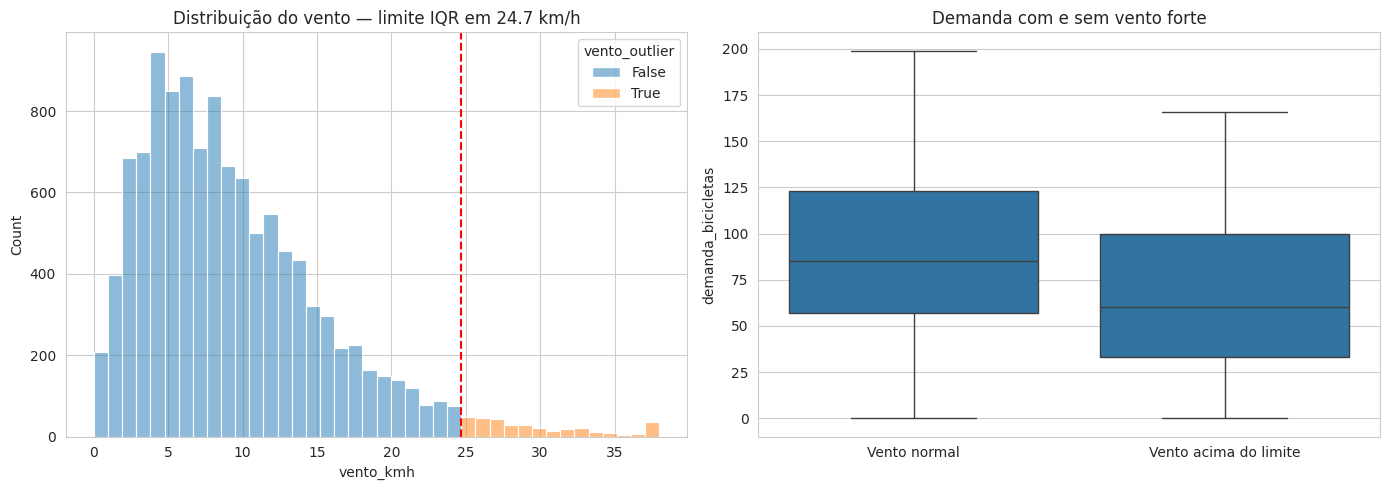

In [12]:
# Investigando os outliers de vento: são erro ou condição real?
inf, sup = limites_iqr(df_train['vento_kmh'])
df_train['vento_outlier'] = df_train['vento_kmh'] > sup

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=df_train, x='vento_kmh', hue='vento_outlier', bins=40, ax=axes[0])
axes[0].axvline(sup, color='red', linestyle='--')
axes[0].set_title(f'Distribuição do vento — limite IQR em {sup:.1f} km/h')

sns.boxplot(data=df_train, x='vento_outlier', y=target, ax=axes[1])
axes[1].set_xticks([0, 1], ['Vento normal', 'Vento acima do limite'])
axes[1].set_xlabel('')
axes[1].set_title('Demanda com e sem vento forte')
plt.tight_layout()
plt.show()

### 4.3.3 Horas com demanda zero

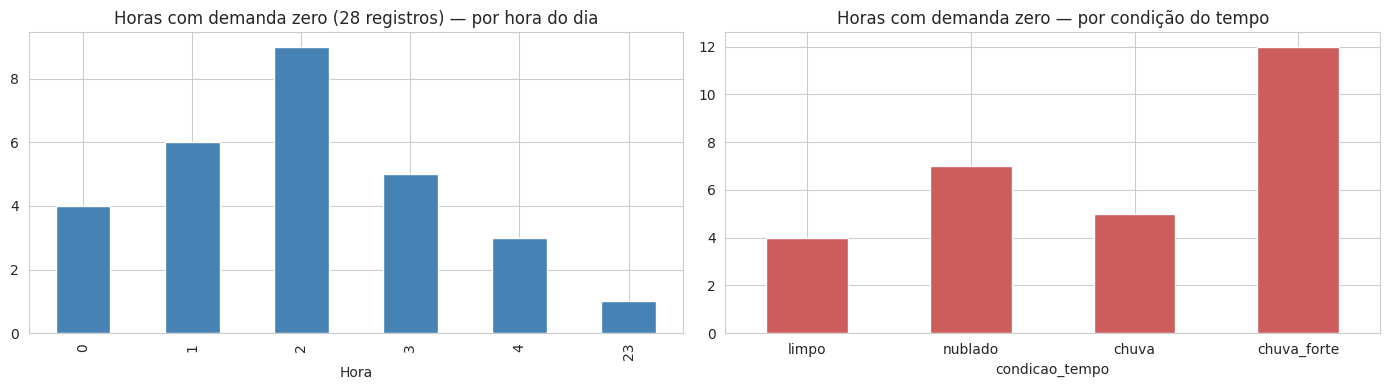

In [13]:
# Verificando quando ocorrem as horas com demanda zero
zeros = df_train[df_train[target] == 0]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
zeros['data_hora'].dt.hour.value_counts().sort_index().plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title(f'Horas com demanda zero ({len(zeros)} registros) — por hora do dia')
axes[0].set_xlabel('Hora')

zeros['condicao_tempo'].value_counts().reindex(['limpo', 'nublado', 'chuva', 'chuva_forte'], fill_value=0).plot(kind='bar', ax=axes[1], color='indianred')
axes[1].set_title('Horas com demanda zero — por condição do tempo')
axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

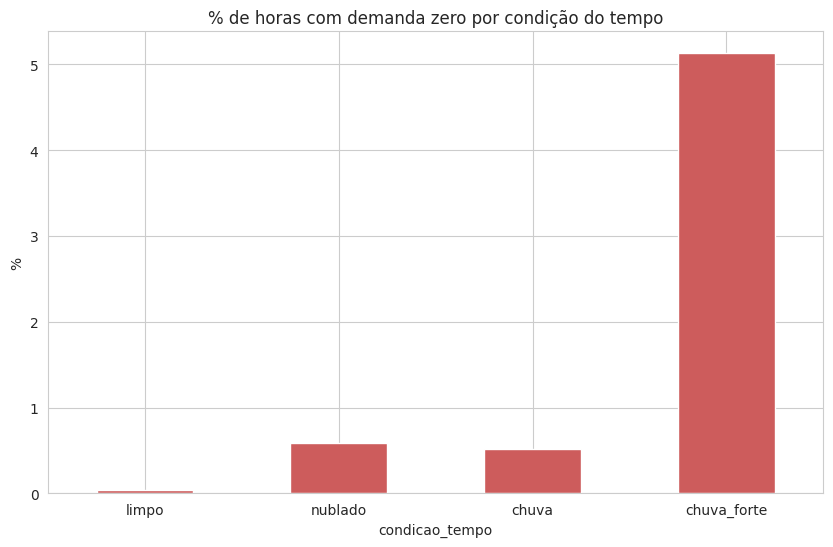

In [14]:
# Calculando a proporção de horas com demanda zero por condição do tempo
prop_zeros = (df_train.groupby('condicao_tempo')[target]
              .apply(lambda s: (s == 0).mean() * 100)
              .reindex(['limpo', 'nublado', 'chuva', 'chuva_forte']))

prop_zeros.plot(kind='bar', color='indianred')
plt.title('% de horas com demanda zero por condição do tempo')
plt.ylabel('%')
plt.xticks(rotation=0)
plt.show()

### 4.3.4 Conclusão — qualidade dos dados

- A base não apresenta valores nulos, linhas duplicadas nem horas faltantes: são 24 registros por dia em todo o período.
- Todos os valores estão dentro de faixas fisicamente plausíveis.
- **Outliers de vento (2,9% do treino) foram mantidos.** Eles formam a cauda natural da distribuição e afetam a demanda: a mediana cai de cerca de 85 para cerca de 60 locações com vento acima de 24,7 km/h. Removê-los impediria o modelo de aprender esse efeito e de lidar com vento forte no teste. Observa-se um acúmulo no valor máximo (38 km/h), que sugere truncamento na coleta.
- **As 28 horas com demanda zero foram mantidas.** Elas ocorrem apenas na madrugada (23h–4h) e são proporcionalmente mais frequentes com chuva forte, o que é coerente com o comportamento esperado.
- **Nenhuma linha foi removida.**

## 4.4 Comportamento da demanda

### 4.4.1 Demanda por hora e tipo de dia

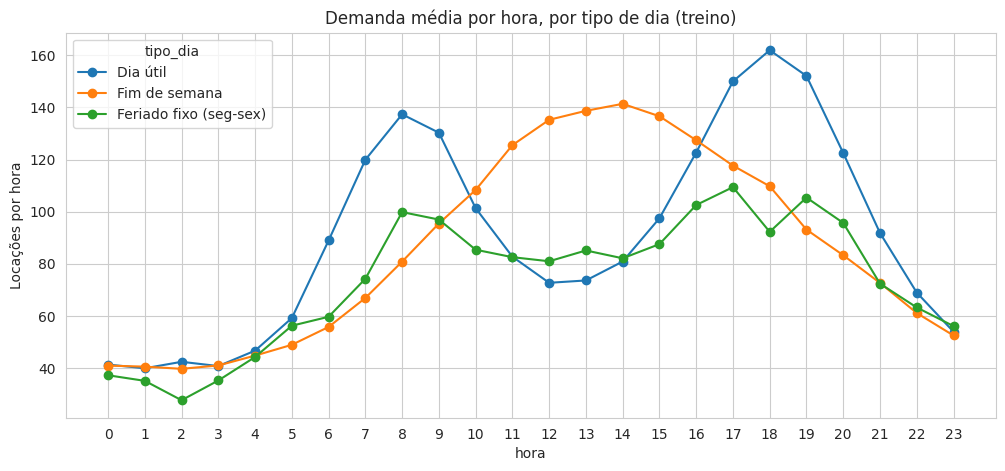

,Dias no treino,Demanda média,Índice de pico
tipo_dia,,,
Dia útil,334,90.84,1.74
Feriado fixo (seg-sex),7,73.67,1.15
Feriado móvel (seg-sex),7,92.77,1.90
Fim de semana,138,85.78,0.69


In [15]:
# Feriados nacionais de data fixa (mês, dia) e feriados móveis do período de treino — fonte: calendário oficial brasileiro
FERIADOS_FIXOS = {(1, 1), (4, 21), (5, 1), (9, 7), (10, 12), (11, 2), (11, 15), (11, 20), (12, 25)}
FERIADOS_MOVEIS = ['2024-02-12', '2024-02-13', '2024-03-29', '2024-05-30', '2025-03-03', '2025-03-04', '2025-04-18']

# Classificando cada hora do treino pelo tipo de dia (colunas auxiliares, usadas apenas na EDA)
df_train['hora'] = df_train['data_hora'].dt.hour
df_train['mes'] = df_train['data_hora'].dt.month
df_train['ano'] = df_train['data_hora'].dt.year
fim_de_semana = df_train['data_hora'].dt.dayofweek >= 5
feriado_fixo = pd.Series([md in FERIADOS_FIXOS for md in zip(df_train['mes'], df_train['data_hora'].dt.day)], index=df_train.index)
feriado_movel = df_train['data_hora'].dt.normalize().isin(pd.to_datetime(FERIADOS_MOVEIS))
df_train['tipo_dia'] = np.select([fim_de_semana, feriado_fixo, feriado_movel],
                                 ['Fim de semana', 'Feriado fixo (seg-sex)', 'Feriado móvel (seg-sex)'], default='Dia útil')

# Perfil horário médio por tipo de dia
perfil = df_train.pivot_table(index='hora', columns='tipo_dia', values=target)
perfil[['Dia útil', 'Fim de semana', 'Feriado fixo (seg-sex)']].plot(marker='o', figsize=(12, 5))
plt.title('Demanda média por hora, por tipo de dia (treino)')
plt.ylabel('Locações por hora')
plt.xticks(range(24))
plt.show()

# Índice de pico: demanda nos horários de deslocamento (7-9h e 17-19h) dividida pela demanda do meio do dia (11-15h)
pico = perfil.loc[[7, 8, 9, 17, 18, 19]].mean() / perfil.loc[11:15].mean()
display(pd.DataFrame({'Dias no treino': df_train.groupby('tipo_dia')['data_hora'].apply(lambda s: s.dt.date.nunique()),
                      'Demanda média': df_train.groupby('tipo_dia')[target].mean(),
                      'Índice de pico': pico}).round(2))

### 4.4.2 Demanda por condição do tempo

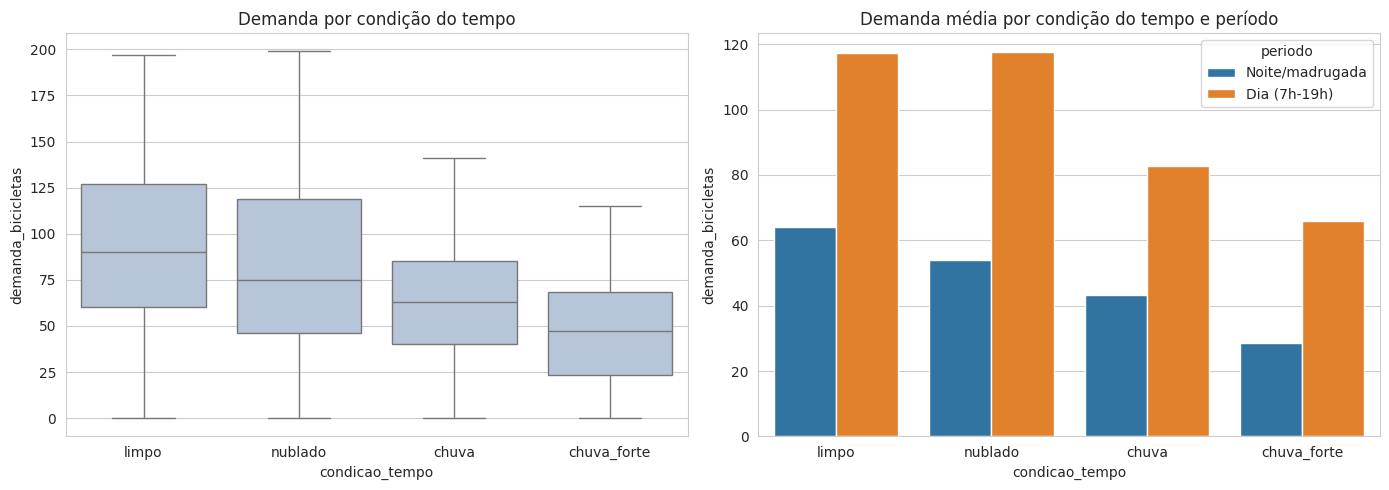

In [16]:
# Comparando a demanda por condição do tempo, dentro e fora dos horários de maior movimento
ordem = ['limpo', 'nublado', 'chuva', 'chuva_forte']
df_train['periodo'] = np.where(df_train['hora'].between(7, 19), 'Dia (7h-19h)', 'Noite/madrugada')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df_train, x='condicao_tempo', y=target, order=ordem, color='lightsteelblue', ax=axes[0])
axes[0].set_title('Demanda por condição do tempo')
sns.barplot(data=df_train, x='condicao_tempo', y=target, hue='periodo', order=ordem, errorbar=None, ax=axes[1])
axes[1].set_title('Demanda média por condição do tempo e período')
plt.tight_layout()
plt.show()

### 4.4.3 Demanda por temperatura, umidade e vento

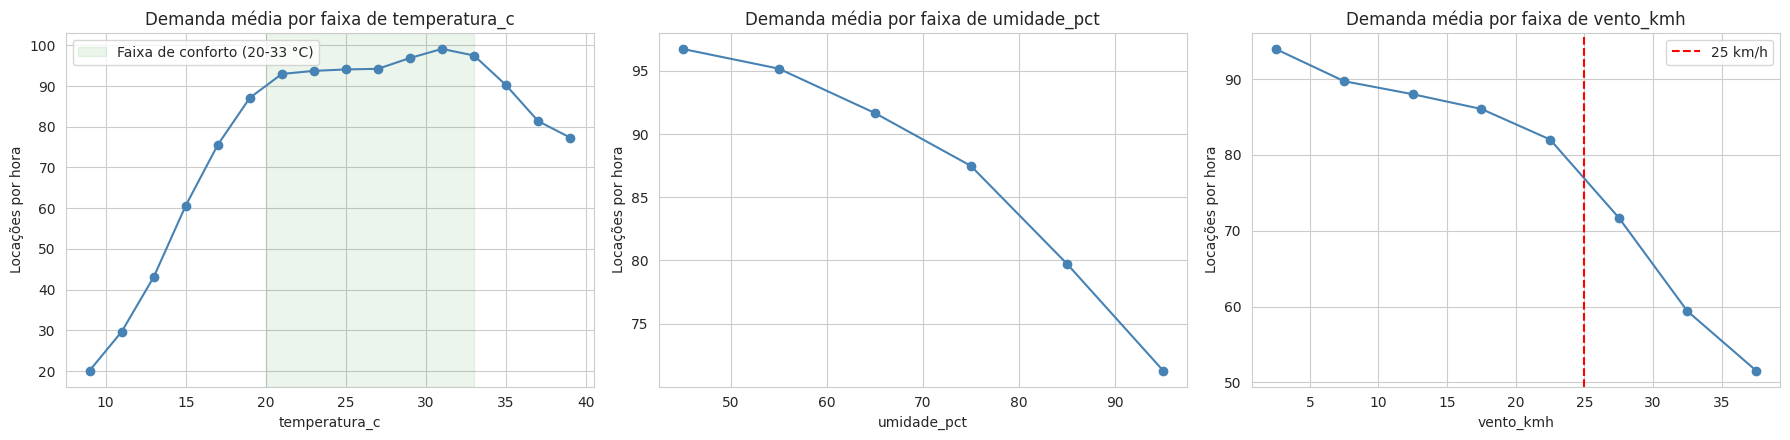

In [17]:
# Demanda média por faixas de cada variável meteorológica (revela relações não lineares)
faixas = {'temperatura_c': range(6, 47, 2), 'umidade_pct': range(30, 101, 10), 'vento_kmh': range(0, 41, 5)}

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (c, bins) in zip(axes, faixas.items()):
    media = df_train.groupby(pd.cut(df_train[c], list(bins), include_lowest=True), observed=True)[target].agg(['mean', 'size'])
    media = media.loc[media['size'] >= 30, 'mean']          # ignora faixas com poucas observações
    ax.plot([i.mid for i in media.index], media.values, marker='o', color='steelblue')
    ax.set_title(f'Demanda média por faixa de {c}')
    ax.set_xlabel(c)
    ax.set_ylabel('Locações por hora')
axes[0].axvspan(20, 33, color='green', alpha=0.08, label='Faixa de conforto (20-33 °C)')
axes[0].legend()
axes[2].axvline(25, color='red', linestyle='--', label='25 km/h')
axes[2].legend()
plt.tight_layout()
plt.show()

### 4.4.4 Evolução mensal

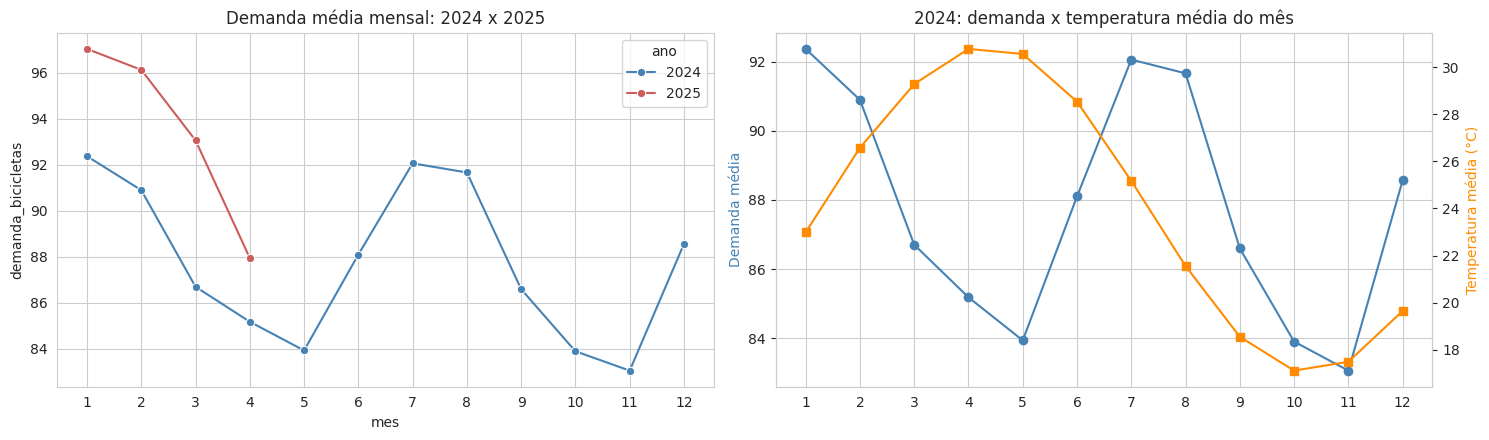

Diferença média 2025 - 2024 (jan-abr): +4.8 locações/h


In [18]:
# Demanda média mensal por ano e relação com a temperatura média do mês
mensal = df_train.groupby(['ano', 'mes'])[[target, 'temperatura_c']].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.lineplot(data=mensal, x='mes', y=target, hue='ano', marker='o', palette=['steelblue', 'indianred'], ax=axes[0])
axes[0].set_title('Demanda média mensal: 2024 x 2025')
axes[0].set_xticks(range(1, 13))

m24 = mensal[mensal['ano'] == 2024]
axes[1].plot(m24['mes'], m24[target], marker='o', color='steelblue')
axes[1].set_ylabel('Demanda média', color='steelblue')
ax2 = axes[1].twinx()
ax2.plot(m24['mes'], m24['temperatura_c'], marker='s', color='darkorange')
ax2.set_ylabel('Temperatura média (°C)', color='darkorange')
ax2.grid(False)
axes[1].set_title('2024: demanda x temperatura média do mês')
axes[1].set_xticks(range(1, 13))
plt.tight_layout()
plt.show()

comparavel = mensal[mensal['mes'] <= 4].pivot(index='mes', columns='ano', values=target)
print(f"Diferença média 2025 - 2024 (jan-abr): {(comparavel[2025] - comparavel[2024]).mean():+.1f} locações/h")

### 4.4.5 Correlações

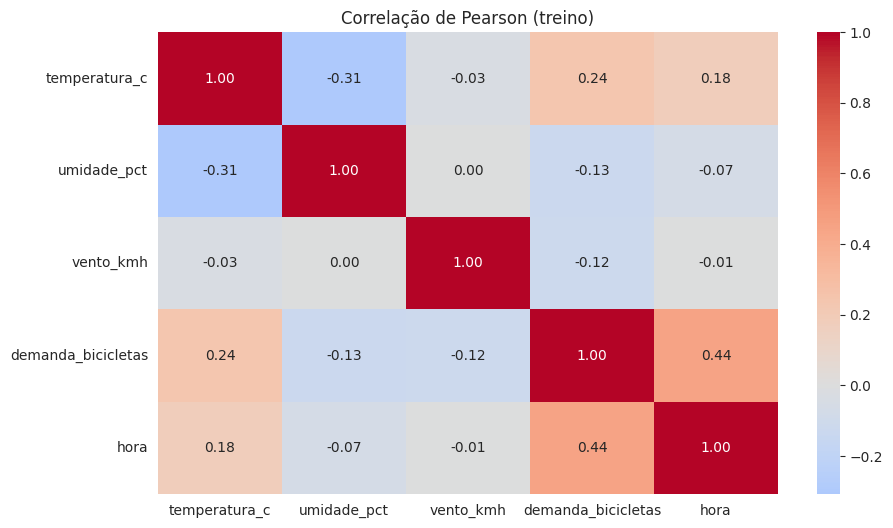

In [19]:
# Correlação linear entre as variáveis numéricas
sns.heatmap(df_train[num_features + ['hora']].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlação de Pearson (treino)')
plt.show()

## 4.5 Hipóteses

**H1 — O perfil horário depende do tipo de dia.** Em dias úteis há dois picos de deslocamento (≈137 locações/h às 8h e ≈162 às 18h). Nos fins de semana há um pico único no início da tarde (≈140 entre 13h e 14h). Feriados nacionais de data fixa que caem de segunda a sexta ficam próximos do perfil de fim de semana (índice de pico 1,15, contra 1,74 dos dias úteis e 0,69 dos fins de semana), enquanto os feriados móveis se comportam como dias úteis (1,90). *Evidência: 4.4.1.*

**H2 — Chuva e vento forte reduzem a demanda, e a chuva pesa mais nos horários de movimento.** A média cai de forma gradual: ≈94 (limpo), ≈82 (nublado), ≈64 (chuva) e ≈47 (chuva forte). Entre 7h e 19h a chuva forte tira ≈52 locações/h; à noite, ≈36. O vento só reduz a demanda de forma clara acima de ~25 km/h. *Evidência: 4.4.2, 4.3.2 e 4.4.3.*

**H3 — O efeito da temperatura é não linear.** A demanda sobe rápido até ~20 °C (de menos de 30 locações/h abaixo de 10 °C para mais de 90), fica num platô entre 20 e 33 °C e volta a cair no calor extremo. Por isso a correlação linear com a temperatura é baixa (0,24), embora o efeito seja forte. A sazonalidade mensal acompanha a temperatura: os vales de demanda coincidem com os meses mais quentes (abril–maio, ≈31 °C) e mais frios (outubro–novembro, ≈17 °C). *Evidência: 4.4.3, 4.4.4 e 4.4.5.*

**H4 — O patamar de demanda de 2025 é mais alto que o de 2024.** Nos meses comparáveis (janeiro a abril), 2025 fica em média 4,8 locações/h acima de 2024, com as curvas praticamente paralelas. *Evidência: 4.4.4.*

# 5. Baseline

## 5.1 Representação da data/hora e da variável categórica

O baseline usa **apenas os atributos originais**. A `data_hora` é decomposta nos componentes diretos `hora`, `dia_semana` e `mes`, e a representação segue o que cada algoritmo exige:

- **Modelo linear (Ridge):** `condicao_tempo`, `hora`, `dia_semana` e `mes` em *one-hot* (um número cru faria o modelo supor que a demanda cresce linearmente das 0h às 23h) e variáveis numéricas padronizadas.
- **Modelo de árvores (seção 8):** `condicao_tempo` em *one-hot* e os componentes de data como inteiros, pois árvores fazem cortes e não supõem linearidade.

Todo o pré-processamento fica dentro de um `Pipeline`, de modo que `OneHotEncoder` e `StandardScaler` são ajustados **somente no treino**.

In [20]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42

def representar_originais(X):
    """Representação do baseline: as 5 entradas originais, com a data/hora decomposta."""
    d = pd.to_datetime(X['data_hora'])
    A = X.drop(columns='data_hora').copy()
    A['hora'], A['dia_semana'], A['mes'] = d.dt.hour, d.dt.dayofweek, d.dt.month
    return A

display(representar_originais(X_train).head(3))

,temperatura_c,umidade_pct,vento_kmh,condicao_tempo,hora,dia_semana,mes
0,20.8,84.1,8.2,nublado,0,0,1
1,18.7,65.5,7.4,limpo,1,0,1
2,13.1,68.8,3.8,limpo,2,0,1


## 5.2 Pipeline e protocolo de avaliação

In [21]:
# Modelos e hiperparâmetros fixos em todos os experimentos
modelos = {'Ridge': Ridge(alpha=1.0),
           'HistGradientBoosting': HistGradientBoostingRegressor(random_state=RANDOM_STATE)}

def remover_colunas(A, colunas):
    return A.drop(columns=list(colunas))

def montar_pipeline(nome_modelo, func_atributos, remover=()):
    """Atributos -> pré-processamento adequado ao algoritmo -> modelo."""
    linear = nome_modelo == 'Ridge'
    categoricas = ['condicao_tempo'] + (['hora', 'dia_semana', 'mes'] if linear else [])
    pre = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categoricas)],
                            remainder=StandardScaler() if linear else 'passthrough')
    return Pipeline([('atributos', FunctionTransformer(func_atributos)),
                     ('remover', FunctionTransformer(remover_colunas, kw_args={'colunas': remover})),
                     ('pre', pre),
                     ('modelo', clone(modelos[nome_modelo]))])

resultados = []

def avaliar(experimento, nome_modelo, func_atributos, remover=(), registrar=True):
    """Treina só no treino, mede na validação e registra MAE, RMSE e R²."""
    pipe = montar_pipeline(nome_modelo, func_atributos, remover).fit(X_train, y_train)
    pred = pipe.predict(X_val)
    linha = {'Experimento': experimento, 'Modelo': nome_modelo,
             'MAE': mean_absolute_error(y_val, pred),
             'RMSE': np.sqrt(mean_squared_error(y_val, pred)),
             'R²': r2_score(y_val, pred)}
    if registrar:
        resultados.append(linha)
    return pipe, linha

## 5.3 Resultados do baseline

In [22]:
# Baseline: Ridge com os atributos originais
_, base_ridge = avaliar('Baseline (atributos originais)', 'Ridge', representar_originais)
display(pd.DataFrame(resultados).round(3))

,Experimento,Modelo,MAE,RMSE,R²
0,Baseline (atributos originais),Ridge,16.323,20.579,0.725


O Ridge com os atributos originais explica cerca de 72% da variância (RMSE ≈ 20,6). Ele soma efeitos independentes de hora, dia da semana, mês e clima; por isso não consegue representar que a curva horária muda conforme o tipo de dia (H1) nem os efeitos não lineares do clima (H2 e H3).

# 6. Engenharia de atributos

## 6.1 Função `criar_atributos`

Uma única função gera todos os atributos derivados **a partir das cinco entradas originais de cada registro**. Ela não usa o alvo, nem valores de outras horas (sem *lags*), nem estatísticas da base; por isso pode ser aplicada do mesmo jeito no treino, na validação e em registros inéditos.

In [23]:
NIVEL_CHUVA = {'limpo': 0, 'nublado': 1, 'chuva': 2, 'chuva_forte': 3}

def criar_atributos(X, feriados=FERIADOS_FIXOS):
    """Recebe as 5 entradas originais e devolve a representação do baseline + 20 atributos derivados."""
    d = pd.to_datetime(X['data_hora'])
    A = representar_originais(X)
    h = A['hora']

    # Grupo 1 — calendário
    feriado = pd.Series([md in feriados for md in zip(d.dt.month, d.dt.day)], index=X.index)
    A['feriado'] = feriado.astype(int)
    A['dia_livre'] = ((A['dia_semana'] >= 5) | feriado).astype(int)
    util = A['dia_livre'] == 0

    # Grupo 2 — perfil horário por tipo de dia: hora cíclica (períodos de 24h e 12h) e interação com dia livre
    for k in (1, 2):
        A[f'hora_sin{k}'] = np.sin(2 * np.pi * k * h / 24)
        A[f'hora_cos{k}'] = np.cos(2 * np.pi * k * h / 24)
        A[f'hora_sin{k}_livre'] = A[f'hora_sin{k}'] * A['dia_livre']
        A[f'hora_cos{k}_livre'] = A[f'hora_cos{k}'] * A['dia_livre']

    # Grupo 3 — faixas horárias
    A['pico_manha'] = (h.between(7, 9) & util).astype(int)
    A['pico_tarde'] = (h.between(17, 19) & util).astype(int)
    A['lazer_tarde'] = (h.between(10, 16) & ~util).astype(int)
    A['madrugada'] = (h <= 5).astype(int)

    # Grupo 4 — clima (efeitos não lineares e interação com o movimento)
    A['chuva_nivel'] = X['condicao_tempo'].map(NIVEL_CHUVA).astype(float)
    A['frio'] = np.clip(20 - A['temperatura_c'], 0, None)
    A['calor'] = np.clip(A['temperatura_c'] - 33, 0, None)
    A['vento_forte'] = np.clip(A['vento_kmh'] - 25, 0, None)
    A['chuva_x_movimento'] = A['chuva_nivel'] * (A['pico_manha'] + A['pico_tarde'] + A['lazer_tarde'])

    # Grupo 5 — nível anual
    A['ano'] = d.dt.year - 2024
    return A

display(criar_atributos(X_train).head(3))

,temperatura_c,umidade_pct,vento_kmh,condicao_tempo,hora,dia_semana,mes,feriado,dia_livre,hora_sin1,hora_cos1,hora_sin1_livre,hora_cos1_livre,hora_sin2,hora_cos2,hora_sin2_livre,hora_cos2_livre,pico_manha,pico_tarde,lazer_tarde,madrugada,chuva_nivel,frio,calor,vento_forte,chuva_x_movimento,ano
0,20.8,84.1,8.2,nublado,0,0,1,1,1,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0,0,0,1,1.0,0.0,0.0,0.0,0.0,0
1,18.7,65.5,7.4,limpo,1,0,1,1,1,0.258819,0.965926,0.258819,0.965926,0.500000,0.866025,0.500000,0.866025,0,0,0,1,0.0,1.3,0.0,0.0,0.0,0
2,13.1,68.8,3.8,limpo,2,0,1,1,1,0.500000,0.866025,0.500000,0.866025,0.866025,0.500000,0.866025,0.500000,0,0,0,1,0.0,6.9,0.0,0.0,0.0,0


## 6.2 Justificativa de cada atributo

| Grupo | Atributos | Transformação | Justificativa (evidência na EDA) |
|---|---|---|---|
| **1. Calendário** | `feriado`, `dia_livre` | feriado nacional de data fixa; fim de semana **ou** feriado | Feriados fixos em dia de semana têm perfil de fim de semana (4.4.1, H1). Fonte pública: calendário oficial de feriados nacionais. |
| **2. Perfil horário × dia** | `hora_sin1`, `hora_cos1`, `hora_sin2`, `hora_cos2` | seno e cosseno da hora, com períodos de 24h e 12h | 23h e 0h são vizinhas, o que a hora crua não expressa. O período de 12h descreve os dois picos diários (4.4.1). |
| | `hora_sin1_livre` … `hora_cos2_livre` | hora cíclica × `dia_livre` | Dá aos dias livres uma curva horária própria, com pico único à tarde (H1). |
| **3. Faixas horárias** | `pico_manha`, `pico_tarde`, `lazer_tarde`, `madrugada` | indicadores de 7–9h e 17–19h em dias úteis, 10–16h em dias livres, 0–5h | Marca os horários em que a demanda muda de patamar: deslocamento, lazer e madrugada (H1). |
| **4. Clima** | `chuva_nivel` | ordem de intensidade 0–3 | A demanda cai de forma gradual de limpo a chuva forte (4.4.2, H2). |
| | `frio`, `calor` | graus abaixo de 20 °C e acima de 33 °C | Efeito não linear: platô entre 20 e 33 °C e queda nos extremos (4.4.3, H3). |
| | `vento_forte` | km/h acima de 25 | O vento só derruba a demanda acima de ~25 km/h (4.3.2 e 4.4.3). |
| | `chuva_x_movimento` | `chuva_nivel` × faixa de movimento | A chuva tira mais locações nos horários de maior movimento (4.4.2). |
| **5. Nível anual** | `ano` | anos desde 2024 | 2025 está cerca de 5 locações/h acima de 2024 nos mesmos meses (4.4.4, H4). |

São **20 atributos derivados** em 5 grupos. Feriados móveis (Carnaval, Sexta-feira Santa, Corpus Christi) foram testados no treino e não mostraram perfil de dia livre (4.4.1), por isso ficaram de fora.

## 6.3 Grupos de atributos e resultado incremental

In [24]:
# Grupos de atributos derivados (usados aqui e na ablação)
grupos = {
    '1. Calendário':            ['feriado', 'dia_livre'],
    '2. Perfil horário × dia':  ['hora_sin1', 'hora_cos1', 'hora_sin2', 'hora_cos2',
                                 'hora_sin1_livre', 'hora_cos1_livre', 'hora_sin2_livre', 'hora_cos2_livre'],
    '3. Faixas horárias':       ['pico_manha', 'pico_tarde', 'lazer_tarde', 'madrugada'],
    '4. Clima':                 ['chuva_nivel', 'frio', 'calor', 'vento_forte', 'chuva_x_movimento'],
    '5. Nível anual':           ['ano'],
}
derivados = [c for cols in grupos.values() for c in cols]
print(f"Atributos derivados: {len(derivados)}")

# Registrando o resultado de cada transformação: grupos adicionados um a um sobre o baseline (Ridge)
incremental = [{'Atributos': 'Baseline', **base_ridge}]
incluidos = []
for nome, cols in grupos.items():
    incluidos += cols
    _, linha = avaliar('', 'Ridge', criar_atributos, remover=[c for c in derivados if c not in incluidos], registrar=False)
    incremental.append({'Atributos': f'+ {nome}', **linha})

display(pd.DataFrame(incremental)[['Atributos', 'MAE', 'RMSE', 'R²']].round(3))

Atributos derivados: 20


,Atributos,MAE,RMSE,R²
0,Baseline,16.323,20.579,0.725
1,+ 1. Calendário,16.262,20.526,0.726
2,+ 2. Perfil horário × dia,11.093,13.878,0.875
3,+ 3. Faixas horárias,10.434,12.981,0.891
4,+ 4. Clima,8.868,11.111,0.920
5,+ 5. Nível anual,7.910,9.935,0.936


A tabela registra o efeito de cada transformação, acumulando os grupos sobre o baseline. Os maiores ganhos vêm do **perfil horário por tipo de dia** (RMSE de ≈20,5 para ≈13,9), do **clima** (≈13,0 para ≈11,1) e do **nível anual** (≈11,1 para ≈9,9). O grupo de calendário quase não muda o resultado sozinho, porque `dia_semana` já está no baseline; o valor de `dia_livre` aparece nos grupos 2 e 3, que são construídos a partir dele.

# 7. Comparação controlada: antes × depois

## 7.1 Mesmo algoritmo, mesma validação, mesmos hiperparâmetros

In [25]:
# Ridge(alpha=1.0), mesmo corte temporal e mesmo pré-processamento; muda apenas o conjunto de atributos
_, eng_ridge = avaliar('Com engenharia de atributos', 'Ridge', criar_atributos)

comp = pd.DataFrame([base_ridge, eng_ridge]).set_index('Experimento')[['MAE', 'RMSE', 'R²']]
comp.loc['Variação (%)'] = (comp.iloc[1] / comp.iloc[0] - 1) * 100
display(comp.round(3))

,MAE,RMSE,R²
Experimento,,,
Baseline (atributos originais),16.323,20.579,0.725
Com engenharia de atributos,7.910,9.935,0.936
Variação (%),-51.539,-51.721,29.113


## 7.2 Discussão

Com o **mesmo algoritmo** (Ridge, `alpha=1.0`), o **mesmo corte temporal** e o **mesmo pré-processamento**, a engenharia de atributos reduziu o MAE de ≈16,3 para ≈7,9 e o RMSE de ≈20,6 para ≈9,9 (queda de cerca de 52% em ambos) e elevou o R² de ≈0,72 para ≈0,94. Como só o conjunto de atributos mudou, o ganho é atribuível à engenharia de atributos, e confirma as hipóteses H1 a H4 que a motivaram.

# 8. Segundo algoritmo

## 8.1 Treinamento

O segundo algoritmo é o `HistGradientBoostingRegressor` (*gradient boosting* de árvores), com os hiperparâmetros padrão do scikit-learn e `random_state=42`. Ele passa pelo mesmo protocolo: mesmo corte temporal, antes e depois da engenharia de atributos.

In [26]:
_, base_hgb = avaliar('Baseline (atributos originais)', 'HistGradientBoosting', representar_originais)
modelo_val, eng_hgb = avaliar('Com engenharia de atributos', 'HistGradientBoosting', criar_atributos)

## 8.2 Comparação de MAE, RMSE e R²

,Experimento,Modelo,MAE,RMSE,R²
0,Baseline (atributos originais),Ridge,16.323,20.579,0.725
1,Com engenharia de atributos,Ridge,7.910,9.935,0.936
2,Baseline (atributos originais),HistGradientBoosting,8.165,10.357,0.930
3,Com engenharia de atributos,HistGradientBoosting,6.905,8.657,0.951


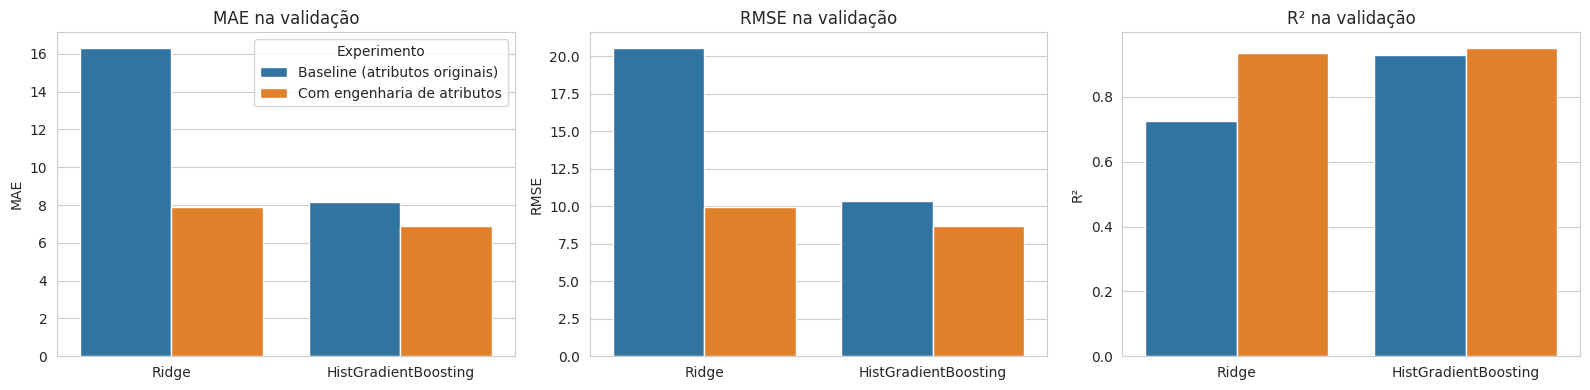

In [27]:
tabela = pd.DataFrame(resultados)
display(tabela.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metrica in zip(axes, ['MAE', 'RMSE', 'R²']):
    sns.barplot(data=tabela, x='Modelo', y=metrica, hue='Experimento', ax=ax)
    ax.set_title(f'{metrica} na validação')
    ax.set_xlabel('')
    if ax is not axes[0]:
        ax.get_legend().remove()
plt.tight_layout()
plt.show()

- **Melhor resultado:** HistGradientBoosting com engenharia de atributos (MAE ≈ 6,9, RMSE ≈ 8,7, R² ≈ 0,95).
- **A engenharia ajuda os dois algoritmos, em graus diferentes.** No Ridge o RMSE cai ≈52%; no boosting, ≈16% (de ≈10,4 para ≈8,7). Árvores aprendem sozinhas interações e limiares, então dependem menos de atributos construídos à mão.
- **Atributos bem construídos compensam um algoritmo simples.** O Ridge com engenharia (RMSE ≈ 9,9) supera o boosting sem engenharia (RMSE ≈ 10,4). A distância entre os algoritmos cai de ≈10 pontos de RMSE no baseline para ≈1,2 depois da engenharia.
- As três métricas apontam a mesma ordem entre os quatro experimentos.

# 9. Ablação

## 9.1 Remoção de grupos de atributos

Cada grupo de atributos derivados é removido isoladamente, mantendo todo o resto igual, e o modelo é treinado de novo. A piora do RMSE em relação ao modelo completo mede a **contribuição marginal** do grupo, isto é, o que ele acrescenta além do que os demais já informam.

In [28]:
def atributos_sem_feriados(X):
    """Mesmos atributos, mas sem a informação de feriados (dia livre = apenas fim de semana)."""
    return criar_atributos(X, feriados=set())

testes = [(nome, criar_atributos, cols) for nome, cols in grupos.items()]
testes.append(('Informação de feriados', atributos_sem_feriados, ['feriado']))

ablacao = []
for nome_modelo, completo in [('Ridge', eng_ridge), ('HistGradientBoosting', eng_hgb)]:
    for nome, func, cols in testes:
        _, linha = avaliar('', nome_modelo, func, remover=cols, registrar=False)
        ablacao.append({'Modelo': nome_modelo, 'Removido': nome, 'MAE': linha['MAE'], 'RMSE': linha['RMSE'], 'R²': linha['R²'],
                        'Δ MAE': linha['MAE'] - completo['MAE'], 'Δ RMSE': linha['RMSE'] - completo['RMSE']})
ablacao = pd.DataFrame(ablacao)
display(ablacao.round(3))

,Modelo,Removido,MAE,RMSE,R²,Δ MAE,Δ RMSE
0,Ridge,1. Calendário,7.913,9.939,0.936,0.003,0.004
1,Ridge,2. Perfil horário × dia,9.525,12.034,0.906,1.614,2.099
2,Ridge,3. Faixas horárias,8.923,11.259,0.918,1.013,1.323
3,Ridge,4. Clima,9.466,12.027,0.906,1.556,2.092
4,Ridge,5. Nível anual,8.868,11.111,0.920,0.958,1.175
5,Ridge,Informação de feriados,7.978,10.094,0.934,0.068,0.159
6,HistGradientBoosting,1. Calendário,6.893,8.637,0.952,-0.012,-0.020
7,HistGradientBoosting,2. Perfil horário × dia,6.908,8.647,0.951,0.003,-0.010
8,HistGradientBoosting,3. Faixas horárias,6.945,8.668,0.951,0.040,0.010
9,HistGradientBoosting,4. Clima,6.942,8.694,0.951,0.037,0.037


## 9.2 Contribuição de cada grupo

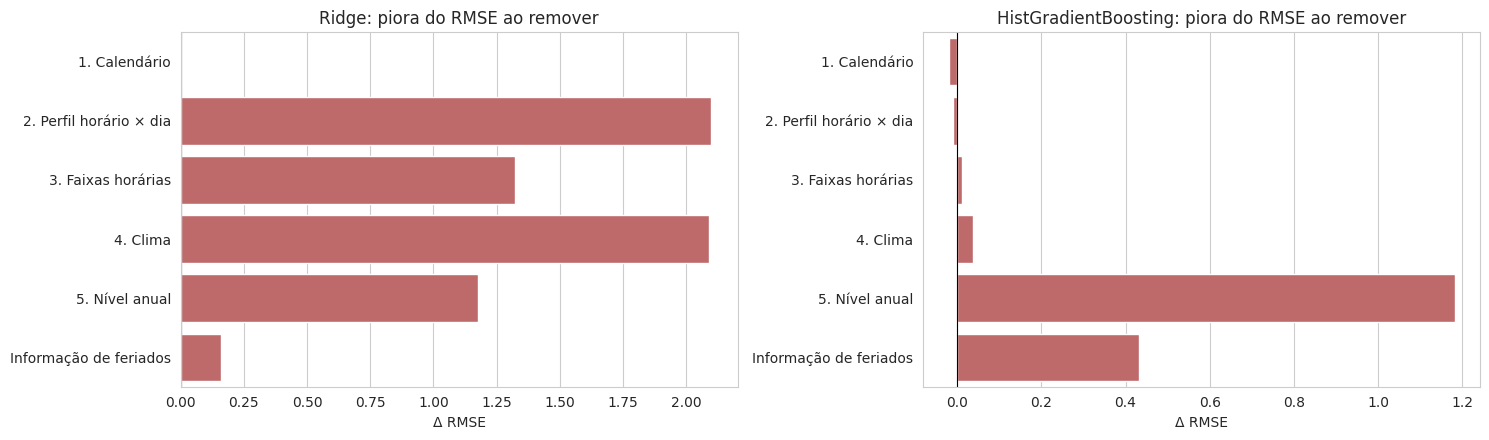

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, nome_modelo in zip(axes, modelos):
    dados = ablacao[ablacao['Modelo'] == nome_modelo]
    sns.barplot(data=dados, y='Removido', x='Δ RMSE', color='indianred', ax=ax)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(f'{nome_modelo}: piora do RMSE ao remover')
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

- **Ridge:** todos os grupos de 2 a 5 contribuem. Remover o perfil horário por tipo de dia ou o clima piora o RMSE em ≈2,1; as faixas horárias, em ≈1,3; o nível anual, em ≈1,2.
- **HistGradientBoosting:** apenas o **nível anual** (Δ RMSE ≈ +1,1) e a **informação de feriados** (≈ +0,4) fazem diferença. Os grupos 2, 3 e 4 ficam dentro do ruído (≈ ±0,03): as árvores reconstroem essas relações a partir das colunas originais. Já o ano e os feriados não existem na representação do baseline, e nenhum algoritmo consegue deduzi-los.
- **Calendário:** remover só as colunas `feriado` e `dia_livre` não muda nada, porque os grupos 2 e 3 carregam a mesma informação. Por isso a linha "Informação de feriados" recalcula todos os atributos sem os feriados, e aí o efeito aparece. A validação tem um único feriado fixo de segunda a sexta (01/05/2025); o teste tem dois (20/11 e 25/12).
- **Leitura crítica:** a ablação mede contribuição marginal. Um grupo com Δ ≈ 0 não é necessariamente inútil; ele pode ser redundante com outro grupo ou, no caso do boosting, com a capacidade do próprio algoritmo.

# 10. Análise crítica dos erros

## 10.1 Resíduos por hora e por condição do tempo

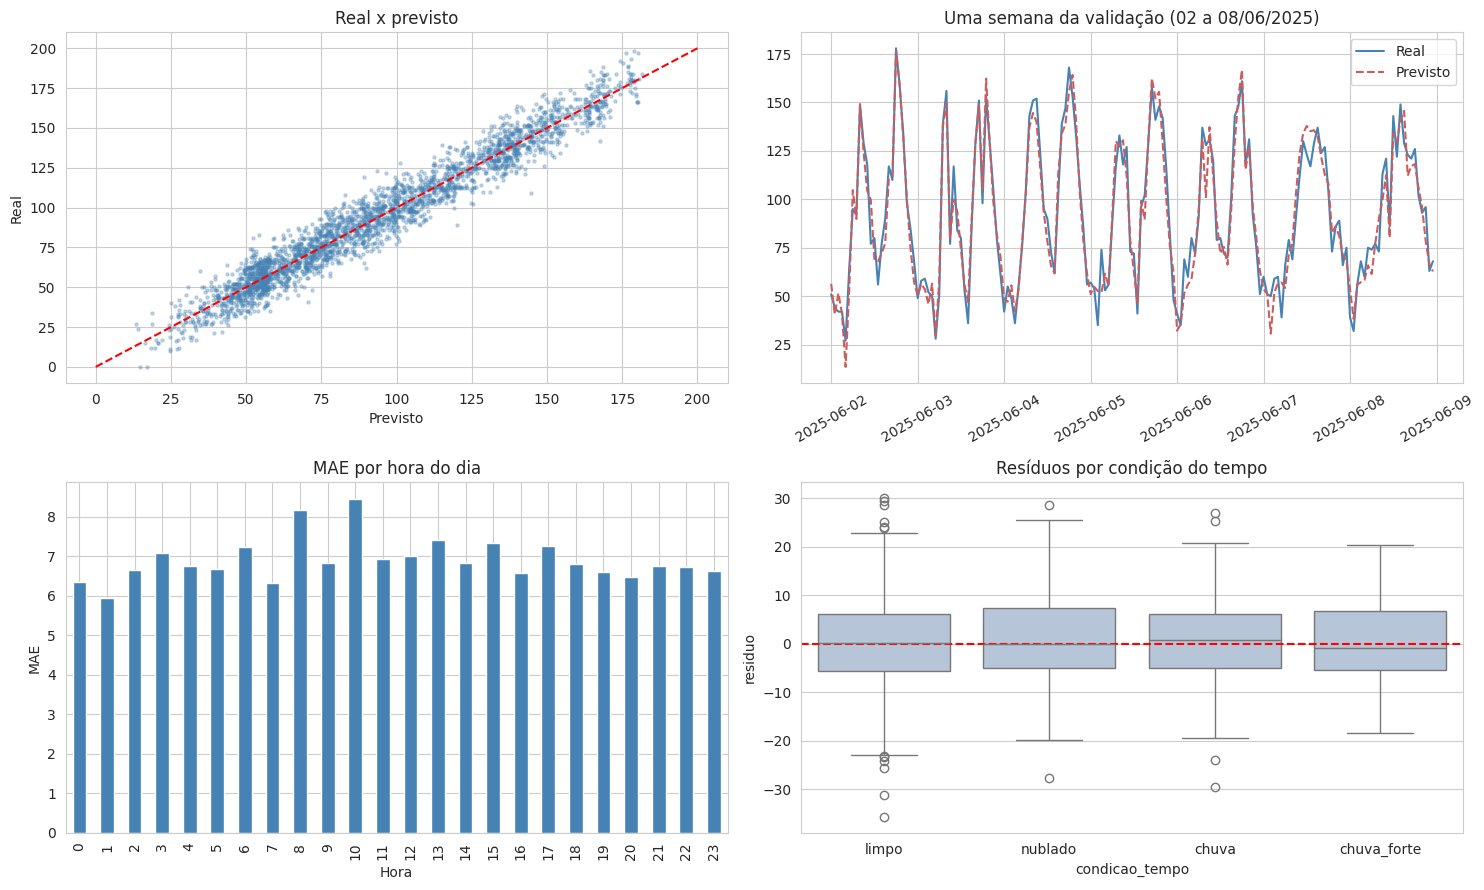

,Horas,Viés,MAE
condicao_tempo,,,
limpo,2387,0.25,6.88
nublado,255,0.99,7.09
chuva,251,0.57,6.89
chuva_forte,59,0.30,7.32


Viés geral: +0.35 | desvio-padrão dos resíduos: 8.65


In [30]:
# Resíduos do melhor modelo (HistGradientBoosting com engenharia de atributos) na validação
erros = X_val.assign(real=y_val, previsto=modelo_val.predict(X_val))
erros['residuo'] = erros['real'] - erros['previsto']
erros['hora'] = erros['data_hora'].dt.hour

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
axes[0, 0].scatter(erros['previsto'], erros['real'], s=5, alpha=0.3, color='steelblue')
axes[0, 0].plot([0, 200], [0, 200], color='red', linestyle='--')
axes[0, 0].set(title='Real x previsto', xlabel='Previsto', ylabel='Real')

semana = erros[erros['data_hora'].between('2025-06-02', '2025-06-08 23:00')]
axes[0, 1].plot(semana['data_hora'], semana['real'], label='Real', color='steelblue')
axes[0, 1].plot(semana['data_hora'], semana['previsto'], label='Previsto', color='indianred', linestyle='--')
axes[0, 1].set_title('Uma semana da validação (02 a 08/06/2025)')
axes[0, 1].tick_params(axis='x', rotation=30)
axes[0, 1].legend()

erros.groupby('hora')['residuo'].apply(lambda r: r.abs().mean()).plot(kind='bar', color='steelblue', ax=axes[1, 0])
axes[1, 0].set(title='MAE por hora do dia', xlabel='Hora', ylabel='MAE')

sns.boxplot(data=erros, x='condicao_tempo', y='residuo', order=ordem, color='lightsteelblue', ax=axes[1, 1])
axes[1, 1].axhline(0, color='red', linestyle='--')
axes[1, 1].set_title('Resíduos por condição do tempo')
plt.tight_layout()
plt.show()

resumo = erros.groupby('condicao_tempo')['residuo'].agg(Horas='size', Viés='mean', MAE=lambda r: r.abs().mean()).reindex(ordem)
display(resumo.round(2))
print(f"Viés geral: {erros['residuo'].mean():+.2f} | desvio-padrão dos resíduos: {erros['residuo'].std():.2f}")

O viés geral é próximo de zero (≈ +0,3) e os pontos se distribuem em torno da diagonal em toda a faixa de demanda. O MAE fica entre ≈6 e ≈9 locações em todas as horas, embora a demanda média varie de ≈47 (madrugada) a ≈149 (18h): o erro absoluto é quase constante, logo o erro **relativo** é maior na madrugada. Por condição do tempo, o MAE vai de ≈6,9 (limpo) a ≈7,4 (chuva forte), esta última com apenas 59 horas na validação. Não há uma faixa horária ou condição com erro sistemático, o que sugere que o erro restante é, em boa parte, ruído dos dados.

## 10.2 O nível anual é um degrau ou uma tendência?

O atributo `ano` supõe que a demanda muda de patamar entre 2024 e 2025. A alternativa seria um crescimento contínuo ao longo dos meses. Para decidir **sem usar a validação**, treinamos o boosting sem nenhuma informação de calendário de longo prazo (sem `ano` e sem `mes`) e olhamos o resíduo médio de cada mês do próprio treino. Se o crescimento fosse contínuo, o resíduo subiria aos poucos; se for um degrau, ele salta na virada do ano.

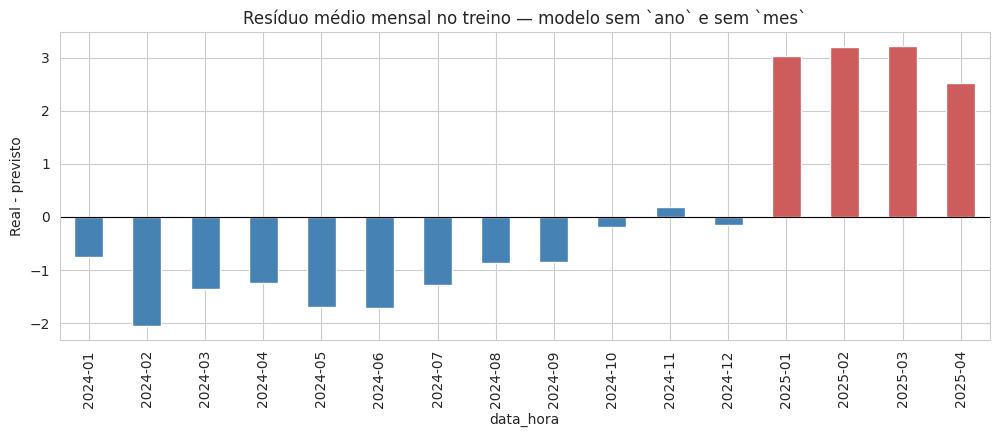

In [31]:
sem_ano = montar_pipeline('HistGradientBoosting', criar_atributos, remover=['ano', 'mes']).fit(X_train, y_train)
residuo_mensal = (y_train - sem_ano.predict(X_train)).groupby(X_train['data_hora'].dt.to_period('M')).mean()

residuo_mensal.plot(kind='bar', figsize=(12, 4), color=['steelblue'] * 12 + ['indianred'] * 4)
plt.axhline(0, color='black', linewidth=0.8)
plt.title('Resíduo médio mensal no treino — modelo sem `ano` e sem `mes`')
plt.ylabel('Real - previsto')
plt.show()

O resíduo médio fica entre ≈ −2 e ≈ 0 durante 2024 e salta para ≈ +3 em janeiro de 2025, mantendo-se nesse nível até abril. O salto na virada do ano é bem maior que a variação ao longo de 2024, o que sustenta tratar o efeito como **mudança de patamar por ano** (`ano`). Há, porém, uma leve subida ao longo de 2024, que não descarta um componente de crescimento gradual.

## 10.3 Limitações

- **Nível anual:** estimado com uma única virada de ano. O modelo supõe que setembro a dezembro de 2025 seguem o patamar de 2025; se houver crescimento gradual, as previsões do teste podem ficar levemente subestimadas. O modelo não serve para extrapolar 2026 sem dados novos.
- **Condições raras:** chuva forte (2% das horas), frio abaixo de 10 °C e calor acima de 38 °C têm poucos exemplos, então o efeito estimado é menos estável. O vento parece truncado em 38 km/h (4.3.4).
- **Feriados:** só os nacionais de data fixa foram incluídos, com base em 7 dias no treino. Feriados móveis não mostraram efeito e feriados locais não foram avaliados.
- **Limiares escolhidos na EDA:** 20 °C, 33 °C, 25 km/h e as faixas horárias foram definidos visualmente, apenas com o treino.
- **Sem histórico recente:** por exigência do enunciado, a previsão usa só as entradas da própria hora. Não há *lags* da demanda, que provavelmente reduziriam o erro.
- **Hiperparâmetros padrão:** não houve ajuste fino, para não usar a validação repetidas vezes como critério de escolha.

# 11. Modelo final e função de predição

## 11.1 Função `prever`

O modelo escolhido é o **HistGradientBoosting com engenharia de atributos**, que teve o menor MAE e o menor RMSE na validação. A função recebe apenas as cinco entradas originais: os atributos derivados são calculados dentro do pipeline, e a previsão é limitada a valores não negativos.

In [32]:
def prever(registros, modelo):
    """Prevê a demanda para registros inéditos contendo apenas as 5 entradas originais."""
    X = pd.DataFrame(registros).copy()
    faltando = [c for c in features if c not in X.columns]
    if faltando:
        raise ValueError(f"Colunas ausentes: {faltando}")
    desconhecidas = set(X['condicao_tempo']) - set(NIVEL_CHUVA)
    if desconhecidas:
        raise ValueError(f"condicao_tempo desconhecida: {desconhecidas}")
    X['data_hora'] = pd.to_datetime(X['data_hora'])
    previsao = np.clip(modelo.predict(X[features]), 0, None)   # demanda nunca é negativa
    return pd.DataFrame({'data_hora': X['data_hora'].values, 'previsao_demanda': previsao.round(2)})

# Exemplo: dois registros inéditos, apenas com as entradas originais
novos = [{'data_hora': '2025-09-15 08:00:00', 'temperatura_c': 24.0, 'umidade_pct': 65.0, 'vento_kmh': 8.0, 'condicao_tempo': 'limpo'},
         {'data_hora': '2025-09-14 03:00:00', 'temperatura_c': 15.0, 'umidade_pct': 90.0, 'vento_kmh': 30.0, 'condicao_tempo': 'chuva_forte'}]
display(prever(novos, modelo_val))

,data_hora,previsao_demanda
0,2025-09-15 08:00:00,152.70
1,2025-09-14 03:00:00,0.16


## 11.2 Retreino com a base completa

Com a seleção concluída, o protocolo permite ajustar a versão final com toda a `base_alunos.csv` (treino + validação). Os atributos e os hiperparâmetros não mudam.

In [33]:
modelo_final = montar_pipeline('HistGradientBoosting', criar_atributos).fit(df[features], df[target])
print(f"Modelo final ajustado com {len(df)} registros ({df['data_hora'].min():%d/%m/%Y} a {df['data_hora'].max():%d/%m/%Y})")

Modelo final ajustado com 14616 registros (01/01/2024 a 31/08/2025)


In [36]:
novo = [{'data_hora': '2025-10-03 18:00:00', 'temperatura_c': 22.0,
         'umidade_pct': 60.0, 'vento_kmh': 10.0, 'condicao_tempo': 'nublado'}]
prever(novo, modelo_final)

,data_hora,previsao_demanda
0,2025-10-03 18:00:00,178.54


## 11.3 Geração de `previsoes_teste.csv`

In [35]:
url_teste = "https://raw.githubusercontent.com/marcelleloha/AP2_Modelo_Bicicletas/main/teste_features_sem_alvo.csv"

try:
    df_teste = pd.read_csv(url_teste)
except Exception as erro:
    df_teste = None
    print(f"ATENÇÃO: não foi possível ler {url_teste}\n({erro})\nSuba o arquivo teste_features_sem_alvo.csv no repositório e execute esta célula novamente.")

if df_teste is not None:
    previsoes = prever(df_teste, modelo_final)
    previsoes['data_hora'] = df_teste['data_hora'].values        # mesma ordem e mesmo formato do arquivo de teste

    assert len(previsoes) == len(df_teste), "Quantidade de linhas diferente do arquivo de teste"
    assert previsoes['previsao_demanda'].notna().all() and (previsoes['previsao_demanda'] >= 0).all()

    previsoes.to_csv('previsoes_teste.csv', index=False)
    print(f"previsoes_teste.csv gerado com {len(previsoes)} linhas")
    display(previsoes.head())
    display(previsoes['previsao_demanda'].describe().round(2).to_frame().T)

previsoes_teste.csv gerado com 2928 linhas


,data_hora,previsao_demanda
0,2025-09-01 00:00:00,27.62
1,2025-09-01 01:00:00,49.23
2,2025-09-01 02:00:00,47.44
3,2025-09-01 03:00:00,41.55
4,2025-09-01 04:00:00,61.42


,count,mean,std,min,25%,50%,75%,max
previsao_demanda,2928.0,90.79,43.2,2.73,51.76,90.2,128.09,179.98


# 12. Conclusões

| Experimento (validação: mai–ago/2025) | MAE | RMSE | R² |
|---|---|---|---|
| Ridge — baseline | ≈16,3 | ≈20,6 | ≈0,72 |
| Ridge — com engenharia de atributos | ≈7,9 | ≈9,9 | ≈0,94 |
| HistGradientBoosting — baseline | ≈8,2 | ≈10,4 | ≈0,93 |
| **HistGradientBoosting — com engenharia de atributos** | **≈6,9** | **≈8,7** | **≈0,95** |

1. **As hipóteses da EDA se confirmaram nos modelos.** O perfil horário por tipo de dia (H1), os efeitos graduais e não lineares do clima (H2 e H3) e o patamar anual (H4) viraram atributos que reduziram o erro do Ridge pela metade.
2. **A engenharia de atributos pesou mais que a troca de algoritmo no modelo linear:** o Ridge com engenharia supera o boosting sem engenharia.
3. **A ablação mostrou o que cada algoritmo realmente precisa.** O Ridge depende de todos os grupos; o boosting só precisa do que não consegue deduzir das entradas: o ano e os feriados.
4. **Não houve vazamento:** corte temporal fixo, transformações ajustadas só no treino dentro do `Pipeline`, nenhum atributo derivado do alvo ou de outras horas, e retreino com a base completa apenas depois da seleção.
5. **Modelo final:** HistGradientBoosting com os 20 atributos derivados, retreinado com toda a `base_alunos.csv` e usado em `prever` para gerar `previsoes_teste.csv`.

# 13. Declaração de uso de IA

- **Ferramenta:** Claude (Anthropic).
- **Partes apoiadas:** organização do notebook em seções; código bruto com estrutura pré definida pelo redator da análise exploratória, dos pipelines, da função `criar_atributos`, da ablação e da função `prever`; redação inicial dos textos explicativos; **as ferramentas foram utilizadas somente como apoio e não para execução total do projeto**.
- **Como os resultados foram verificados:** o notebook foi executado de ponta a ponta; as contagens foram conferidas com o enunciado (14.616 registros, 11.664 de treino e 2.952 de validação); todas as métricas são calculadas pelo próprio notebook; as hipóteses e justificativas foram conferidas com os gráficos e tabelas correspondentes; o código foi lido e revisado.